# Real EBSD patterns to a spatial nickel orientation map


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`patterns`，shape `(1, 40, 50, 60, 60)`，dtype `|u1`：Real detector ADU, axes batch,scan_row,scan_column,detector_row,detector_column.；`master_pattern`，shape `(1, 2, 401, 401)`，dtype `|u1`：Independently simulated20keV nickel angular intensity in arbitrary units; axes batch,hemisphere,Lambert_row,Lambert_column; hemisphere0 north,1 south.。未知量为40×50扫描网格的Ni取向单位四元数。

获取模型：独立Ni主衍射图经晶体旋转、Lambert采样和探测器几何投影形成EBSD强度。

如何恢复：src.solvers.reconstruct/index_patterns/refine；Notebook调用visualization.review间接执行全部恢复。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell9–19六组图：原生实测、上游/新取向、PCA、前向图样、维数/PC与直接字典比较。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留6个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。独立模拟master_pattern是校准，不是目标取向GT。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Recover a spatial nickel crystal-orientation map from real electron backscatter diffraction patterns despite noisy bands, crystal symmetry and a large nonlinear orientation search.


## Current benchmark evaluation (v2, 2026-10-29)

The v2 benchmark uses simple input-only2x2 detector averaging, scan-background subtraction, and raw calibrated master-pattern contrast. It no longer compares orientations against the finite PCA/dictionary/refinement trajectory. Each of2000 pattern cosines is checked against an attainable baseline contrast with0.001 numerical quality budget, plus mean quality. This is not angular truth or measured noise. All24 physical cubic representatives and quaternion sign are allowed by the independently rendered model. The original CLAHE/FP16 source stage fixtures remain historical algorithm diagnostics, not the v2 acceptance target.

Reference/source-stage and map-similarity comparisons below are retained as historical v1 diagnostics; they do not assert current v2 acceptance boundaries. Current standalone Judge callers retain the same generic report interface.

## 2. Data

These are existing **real EBSD measurements**, paired with an independently simulated nickel diffraction calibration. The selected scan region is original rows50:90 and columns60:110, zero-based, of a149-row by200-column acquisition containing29800 patterns. This is a native40 by50 crop of scan locations, not the entire original scan and not a resized scan. Each supplied detector pattern remains native60 by60. Only the public2000 patterns may contribute to a scan-derived background estimate; no outside-ROI pattern or hidden label is provided.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| patterns | (1,40,50,60,60) | uint8 | Real detector ADU, axes batch,scan_row,scan_column,detector_row,detector_column. |
| master_pattern | (1,2,401,401) | uint8 | Independently simulated20keV nickel angular intensity in arbitrary units; axes batch,hemisphere,Lambert_row,Lambert_column; hemisphere0 north,1 south. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Material | nickel, cubic high symmetry | phase | Single phase;24 proper rotations. |
| Accelerating voltage | 20 | kV | Matches the master-pattern calibration. |
| Sample tilt | 70 | degree | Source geometry relative to detector tilt0. |
| Detector tilt | 0 | degree | phi=-70degrees in the stated ray model. |
| Detector raw size | 60 by60 | pixels | L=60 and native center indices0..59. |
| Projection center(px,py,pz) | (0.4221,0.2179,0.4954) | dimensionless | Selected source-provided Bruker fractions; distance is normalized by detector height. |
| Detector coordinate convention | row/column centers at integer indices | pixels | The +1/2 terms in the ray equation encode the pixel-center/PC convention. |
| Master projection | square Lambert, no vertical flip | convention | Northern and southern matrices correspond to Z>=0 and Z<0. |
| Master grid | 401 by401 per hemisphere | pixels | Concatenate north then south along columns if using normalized(u,v) above. |
| Master lattice parameter | 0.35236 | nm | Independently supplied nickel simulation parameter. |
| Native scan size | 149 rows by200 columns | samples | Original acquisition, not all released here. |
| Selected native scan rows | 50..89 inclusive | index | Zero-based crop; all selected points evaluated. |
| Selected native scan columns | 60..109 inclusive | index | Zero-based crop. |
| Scan pitch | 1.5 | micrometer | Both scan directions; output retains native spacing. |
| Selected origin | x=90,y=75 | micrometer | x=original_column*1.5,y=original_row*1.5 relative original scan origin. |
| Camera gain | 0 | dB | Selected real acquisition. |
| Exposure | 3500 | microsecond | Acquisition metadata. |
| Detector noise variance | not independently calibrated | ADU squared | No known Poisson count scale or hidden clean-pattern input. |
| Spatial boundary | finite selected rectangle | convention | No periodic scan continuation or spatial alignment. |


The bound data are **2000 real native scan points**, rows50:90/columns60:110 of a149×200gain0dB scan, at1.5µm pitch. Each public detector pattern is native60×60. A separately simulated20keV nickel master calibration provides north/south square-Lambert angular intensity. No actual orientation truth or outside-ROI background is available. All static-background statistics use only these2000public patterns.


## 3. Physics

Recover the nickel crystal orientation at each of2000 native scan locations in a40-row by50-column rectangular region of a real0dB camera-gain acquisition. Each location has a native60 by60 detector pattern. The observations are indirect diffraction intensities, not supplied orientation labels. A separately simulated20keV nickel master pattern is legitimate calibration describing the angular diffraction response.

Let i,j be detector row and column, L the detector size in pixels, and (px,py,pz) the dimensionless Bruker projection center. Define a=i+1/2-L*py, b=j+1/2-L*px, D=L*pz, and phi the detector-minus-sample tilt. The sample-frame ray is


$$
\mathbf r(i,j)=(-\sin(\phi)a+\cos(\phi)D,\ b,\ -\cos(\phi)a-\sin(\phi)D).
$$


For a unit scalar-first quaternion q=(w,x,y,z), its rotation R(q) maps a sample-frame ray into crystal coordinates. The ideal detector intensity is proportional to M(R(q)r/||r||), where M is the known spherical master intensity. The measured pattern also contains spatially varying background and noise. M is supplied as square-Lambert projections of the northern and southern hemispheres. Intensities have arbitrary detector/calibration scales, not calibrated photon counts. The nonlinear dependence on q, weak band contrast and cubic symmetry make the inverse ambiguous.

For completeness the square-Lambert coordinates can be computed as follows. For crystal unit vector (X,Y,Z), let f=sqrt(2(1-|Z|)); let B be the coordinate of larger absolute magnitude among X,Y, S the other coordinate, and sigma=-1 when B<0 and+1 otherwise. Put A=sigma*f/sqrt(2) and C=sigma*f*atan2(sigma*S,|B|)*2sqrt(2)/pi. Take (aL,bL)=(A,C) if |Y|<=|X| and(C,A) otherwise. Coordinates on the concatenated north-left/south-right array are u=aL/2-1/2+1[Z<0], v=bL, both normalized for interpolation; 1[condition] is1 if true and0 otherwise. Hemisphere index0 is north. The supplied array is not a stereographic projection and must not be vertically flipped.


Geometry uses Bruker PC(.4221,.2179,.4954), sample tilt70degrees, detector tilt0. With a=i+.5-L*PCy,b=j+.5-L*PCx,D=L*PCz and phi=-70degrees, sample ray r=(-sin(phi)a+cos(phi)D,b,-cos(phi)a-sin(phi)D). A unit scalar-first quaternion q actively rotates r into crystal coordinates. The calibrated intensity is a bilinear square-Lambert sample of the unit crystal ray. The raw data contain noise/background and unknown intensity scaling, so these maps are model-dependent diffraction inverses.


## 4. Method

Dictionary indexing projects calibrated angular intensities for many possible orientations and matches each experimental pattern to those candidates. A principal-component basis learned from simulated dictionary patterns can reduce the matching dimension while retaining informative band variation. An incremental covariance update avoids storing the complete image dictionary. Local cubochoric orientation search can refine the initial discrete match. Keep preprocessing, quaternion action, detector pixel centers and interpolation conventions consistent.


The selected source configuration is **2degree/102448orientations,512PCA components, internal30²detector sampling,4refinement rounds**, CPUfloat32 matching. It is a concrete configuration of Varley/Rohrer/DeGraef, ScientificReports16,4382(2026), DOI10.1038/s41598-025-34391-8, published4January2026. It is not the paper's1degree DI method reference, not1024components, not all0/12/24dB measurements, and not actual orientation truth. Other paper modes are not shown as computed.


Final selection was upgraded from100PC to512PC after separate original runs and independent public-only forward evaluation: mean cosine100PC0.38316,512PC0.45126,direct DI0.45129. This is model consistency, not measured physical orientation accuracy. The100PC negative comparator is actively recomputed and retained alongside25PC.512PC versus direct mean disorientation0.26375degree,95%0.55434degree,with a few large differences up to59.83degree, so equivalence or truth is not claimed.


### Implemented inverse, original differences and actual experiments

The native detector60² is bilinearly averaged into30²; scan coordinates are never resized. Float16 detector patterns subtract the public-ROI mean, minmax normalize with1e-4, undergo explicit4×4tile/64bin/clip40 CLAHE, then normalize again. Independent master intensities use minmax and8×8tile CLAHE. Source dictionary patterns remove only per-pattern means after projecting the processed master; this is the actual source convention rather than a claim of identical experiment/dictionary preprocessing. A fixed circular detector mask retains716pixels for dictionary matching; refinement uses all900.

Uniform cubochoric sampling maps to unit quaternions and rejects points outside the cubic fundamental zone. Incremental Welford/Chan covariance accumulates simulated dictionary patterns in batches256; eigh supplies the top512eigenvectors. Both dictionary and measured patterns project into that same subspace and are matched by the source's **unnormalized float32 dot product**. No full dictionary image stack, quantization library or domain solver is used. A27candidate cubochoric local search runs4rounds; its semi-edge begins2degrees and halves only on a central winner.

The original source uses linspace(0,30,30)detector centers. A separately proved minimal endpoint correction uses arange30, consistent with the Bruker half-pixel formula. Original unmodified and qualified corrected runs are separately identified. The source right-quaternion FZ mapping happens **before** actual candidate projection/scoring, and the exact scored candidate is returned. It is retained as a candidate heuristic, not asserted to be a physical symmetry equivalence; the independent evaluator uses proper **left** crystal symmetry. All8000actual original center candidates were unchanged, and average dot scores improved27.0249→31.2824;180tiny negative numerical increments down to-7.63e-6mean no strict per-pixel monotonicity is claimed.

The published TSL PC(.4210,.7794,.5049) converts on the square detector to Bruker(.4210,.2206,.5049), distinct from source PC. The active cell below actually runs a complete inverse at that independently known alternative PC and a25component matching/refinement comparison using the freshly learned basis. Neither PC is fitted to hidden orientations. A600s per-cell timeout allows the full CPU comparisons.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,json,time
task=Path.cwd()
if not (task/'src').is_dir(): task=task.parent
if not (task/'src').is_dir(): raise RuntimeError('Execute from task or notebooks directory')
sys.path.insert(0,str(task))
import numpy as np,torch,matplotlib.pyplot as plt
torch.set_num_threads(1)
from src.visualization import review
print('Kernel executable:',sys.executable,'NumPy',np.__version__,'torch',torch.__version__)
figure_dir=Path(os.environ.get('IMAGING_FIGURE_DIR',str(task/'output/review_figures')))


Kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy 2.4.6 torch 2.9.1+cu128


In [2]:
start=time.perf_counter()
figures,measurements=review(task,figure_dir)
print('Complete active review seconds:',time.perf_counter()-start)
print(json.dumps(measurements,indent=2))


Complete active review seconds: 279.3163812999992
{
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "max_disorientation_deg": 2.4148365394514667e-06,
      "mean_disorientation_deg": 1.098291091440116e-07,
      "mean_forward_cosine": 0.45126419887562524
    },
    "thresholds": {
      "max_disorientation_deg": {
        "comparison": "<=",
        "boundary": 0.0001
      },
      "mean_disorientation_deg": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "mean_forward_cosine": {
        "comparison": ">=",
        "boundary": 0.446751556886869
      }
    },
    "errors": []
  },
  "fresh_baseline_seconds": 53.37600189999648,
  "dictionary_count": 102448,
  "comparison25_reused_basis_seconds": 37.70995440000115,
  "paper_pc_full_seconds": 57.47309210000094,
  "paper_pc_bruker": [
    0.421,
    0.22060000000000002,
    0.5049
  ],
  "mean_endpoint_change_deg": 2.2046839656047776,
  "max_local_original_difference_deg": 3.41509458500

### Figure1

Native60² real observations and their actual30²processed patterns, three native scan points. Background uses only the public ROI, and arbitrary detector intensity is not called photon counts.


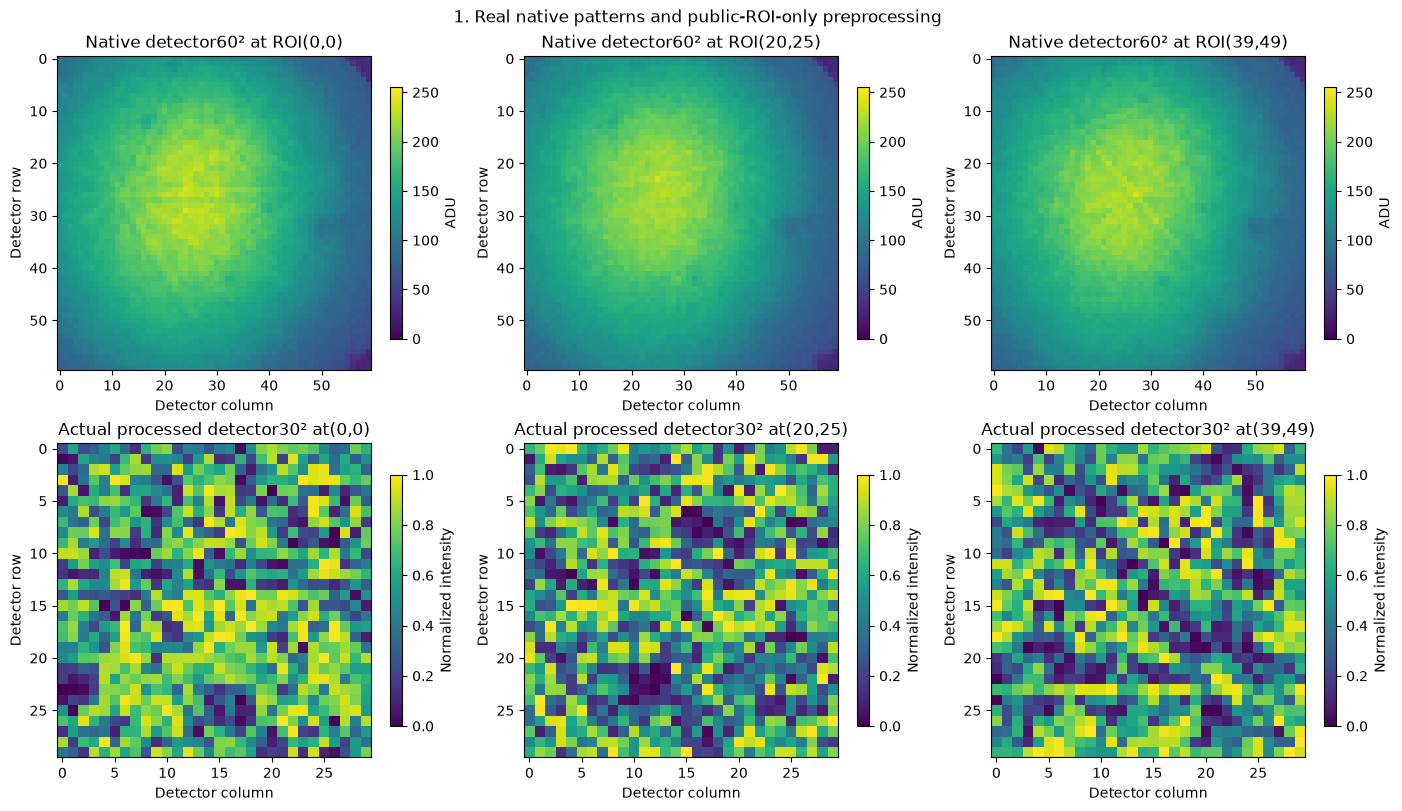

In [3]:
display(figures[0])
plt.close(figures[0])

### Figure2

Original unmodified, original qualified-corrected and fresh local spatial maps. Pole colors sort the absolute crystal components of the sample normal(a≤b≤c), use RGB=(c-b,sqrt2(b-a),sqrt3*a), normalize by max then square-root; red001,green101,blue111. This explicit symmetry-invariant explanatory color is not an external-library IPF plot or measured orientation truth.


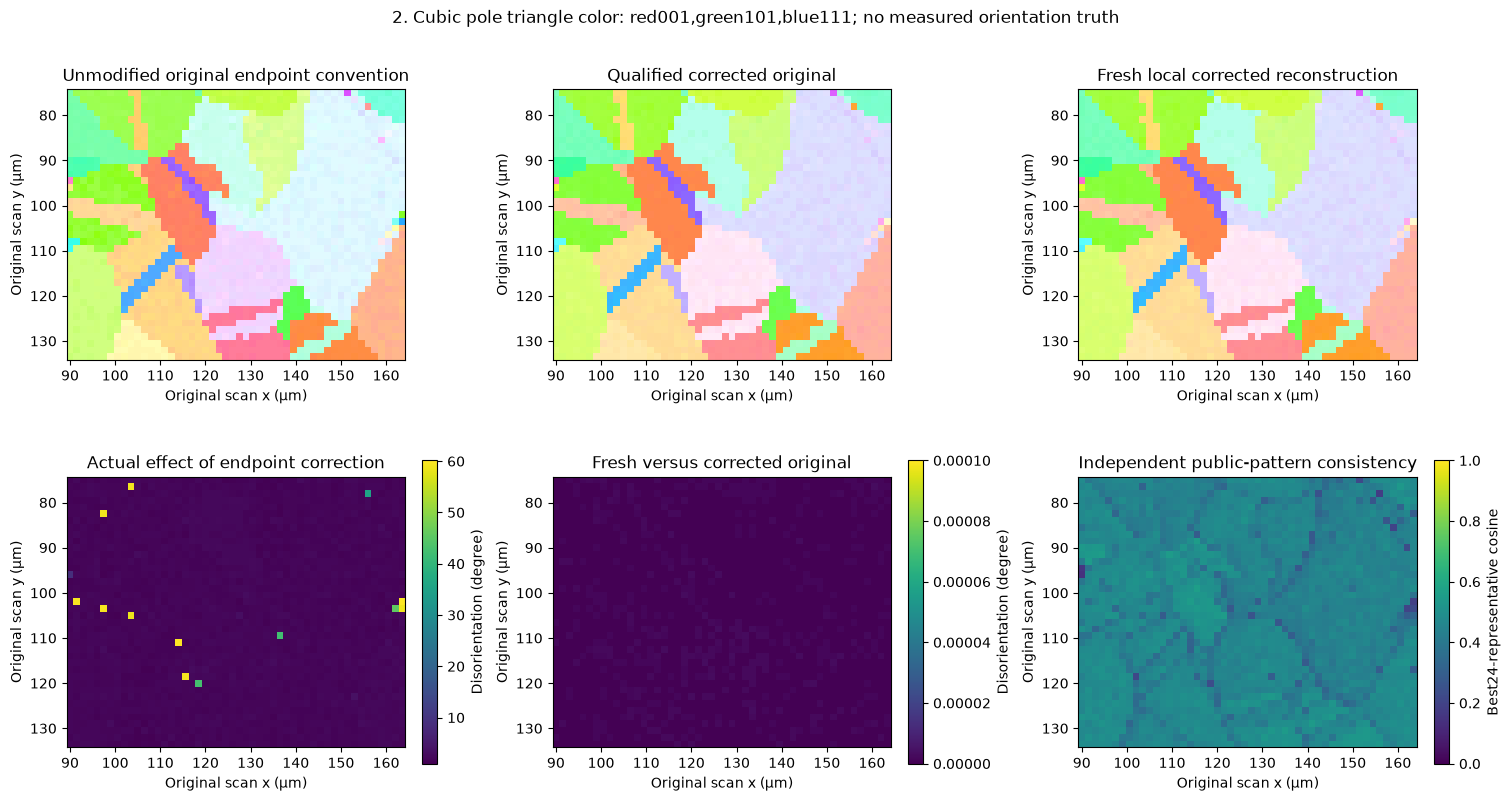

In [4]:
display(figures[1])
plt.close(figures[1])

### Figure3

Actual learned PCA vectors, masked detector domain, covariance spectrum and cumulative eigenvalue fraction. The variance curve describes this simulated dictionary, not independent experimental signal variance or all paper component benchmarks.


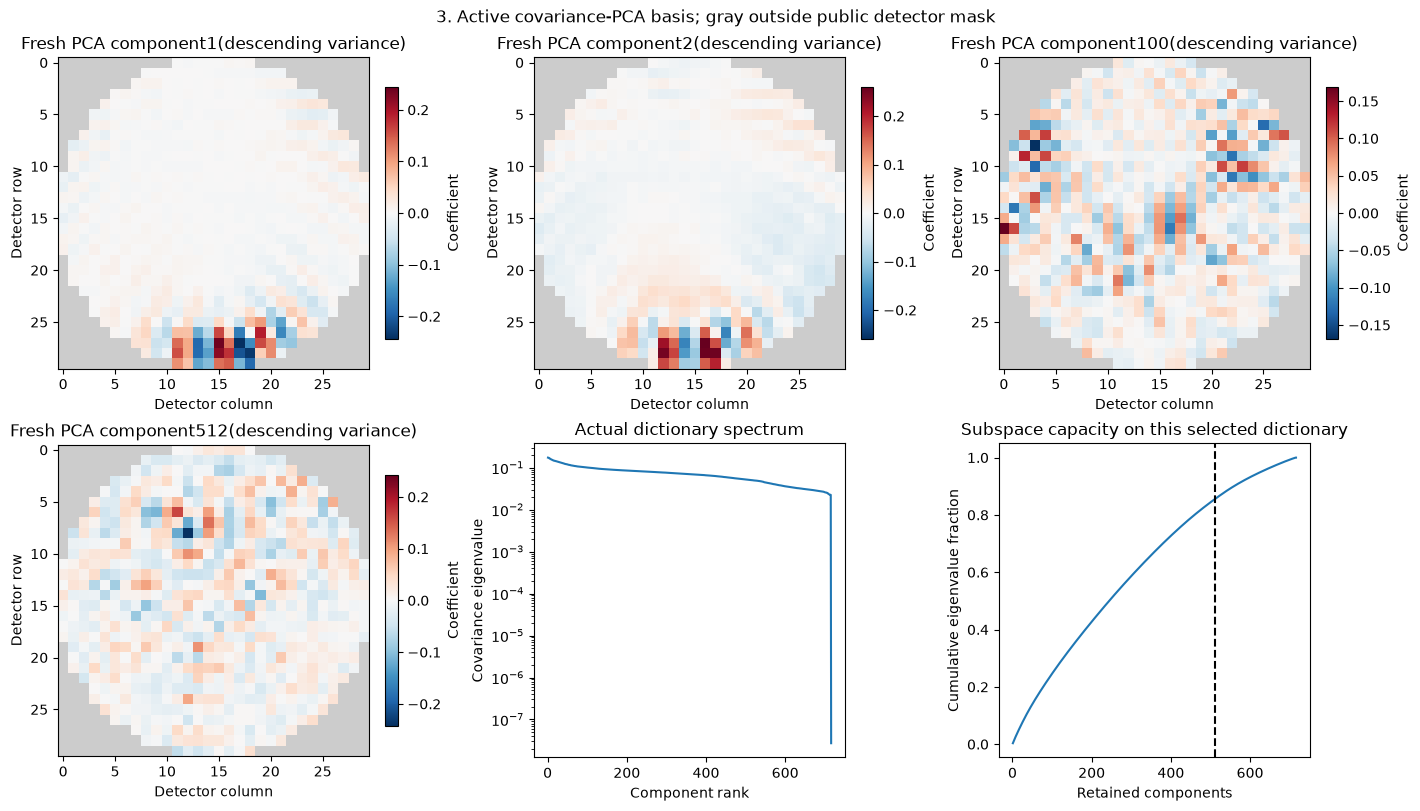

In [5]:
display(figures[2])
plt.close(figures[2])

### Figure4

Observed and freshly forward-projected patterns use separate zero-mean unit-L2 normalization, with identical paired color limits. Their residuals expose limited master/data agreement rather than hiding it with per-example fitted calibration. These use the actual source representative; the Judge additionally maximizes over24physical representatives.


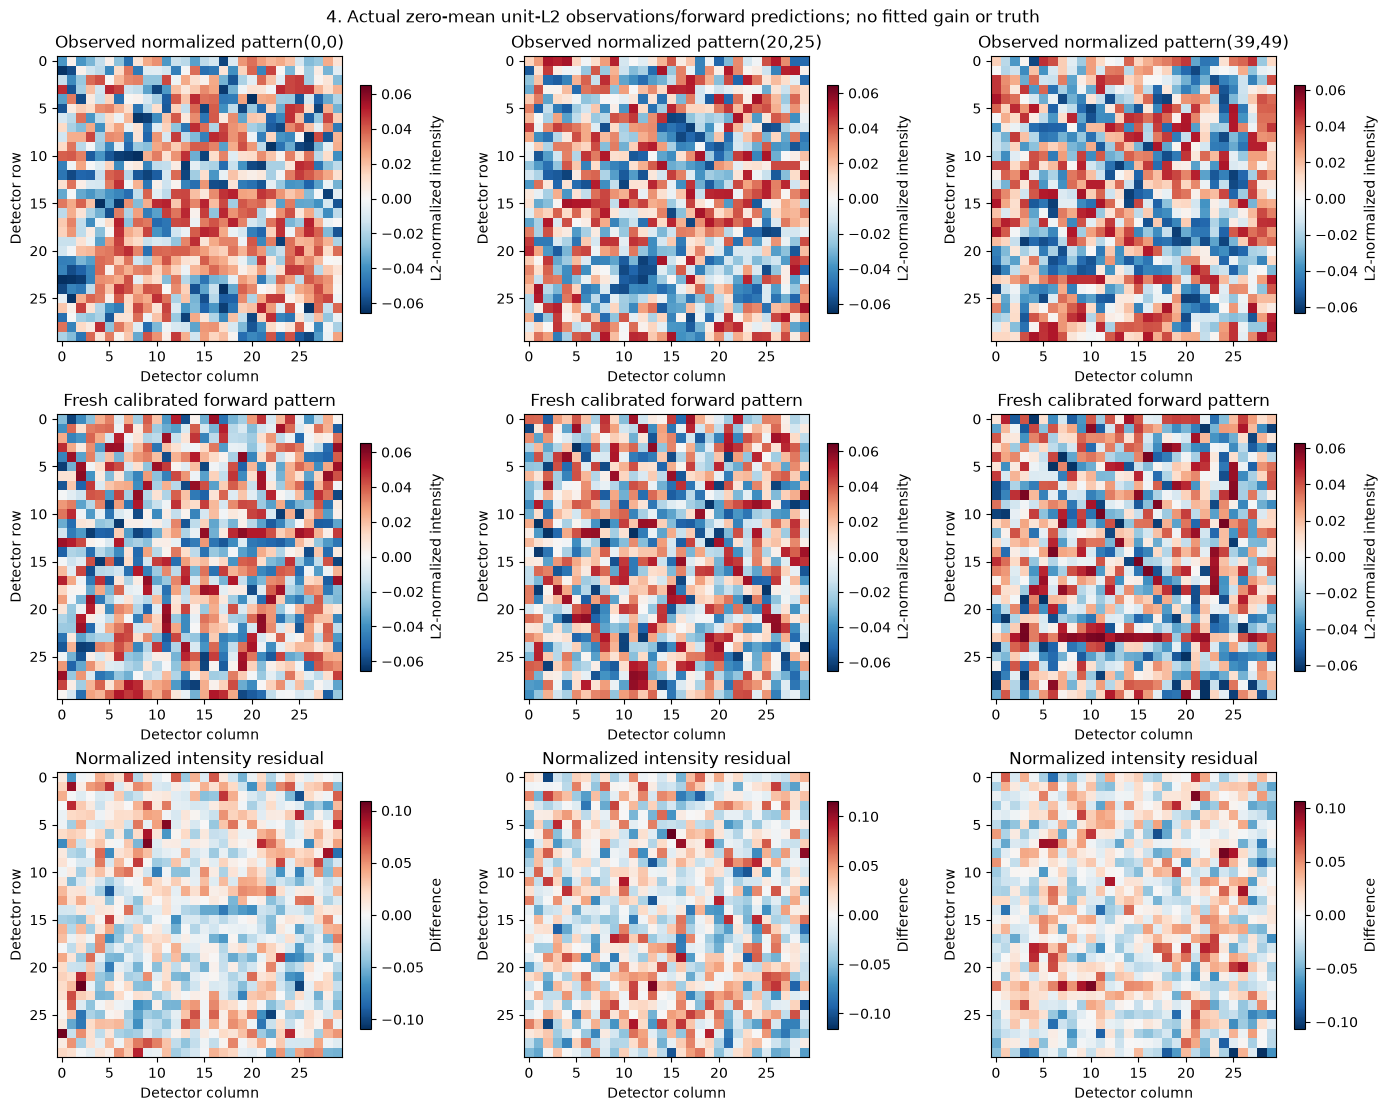

In [6]:
display(figures[3])
plt.close(figures[3])

### Figure5

Actual coarse/refined,25/512component and source/paper-PC comparisons. The25component path reuses the freshly learned basis, so its runtime is explicitly labeled differently from complete inverse runtimes. The original trajectory is a separately captured original run. No paper speedup or actual orientation accuracy is inferred.

The expanded actual sensitivity group also retains fresh100PC versus512PC maps, all-point angular distributions, and full learning/matching/refinement costs;100PC/25PC reuse the fresh covariance basis and are labeled accordingly.


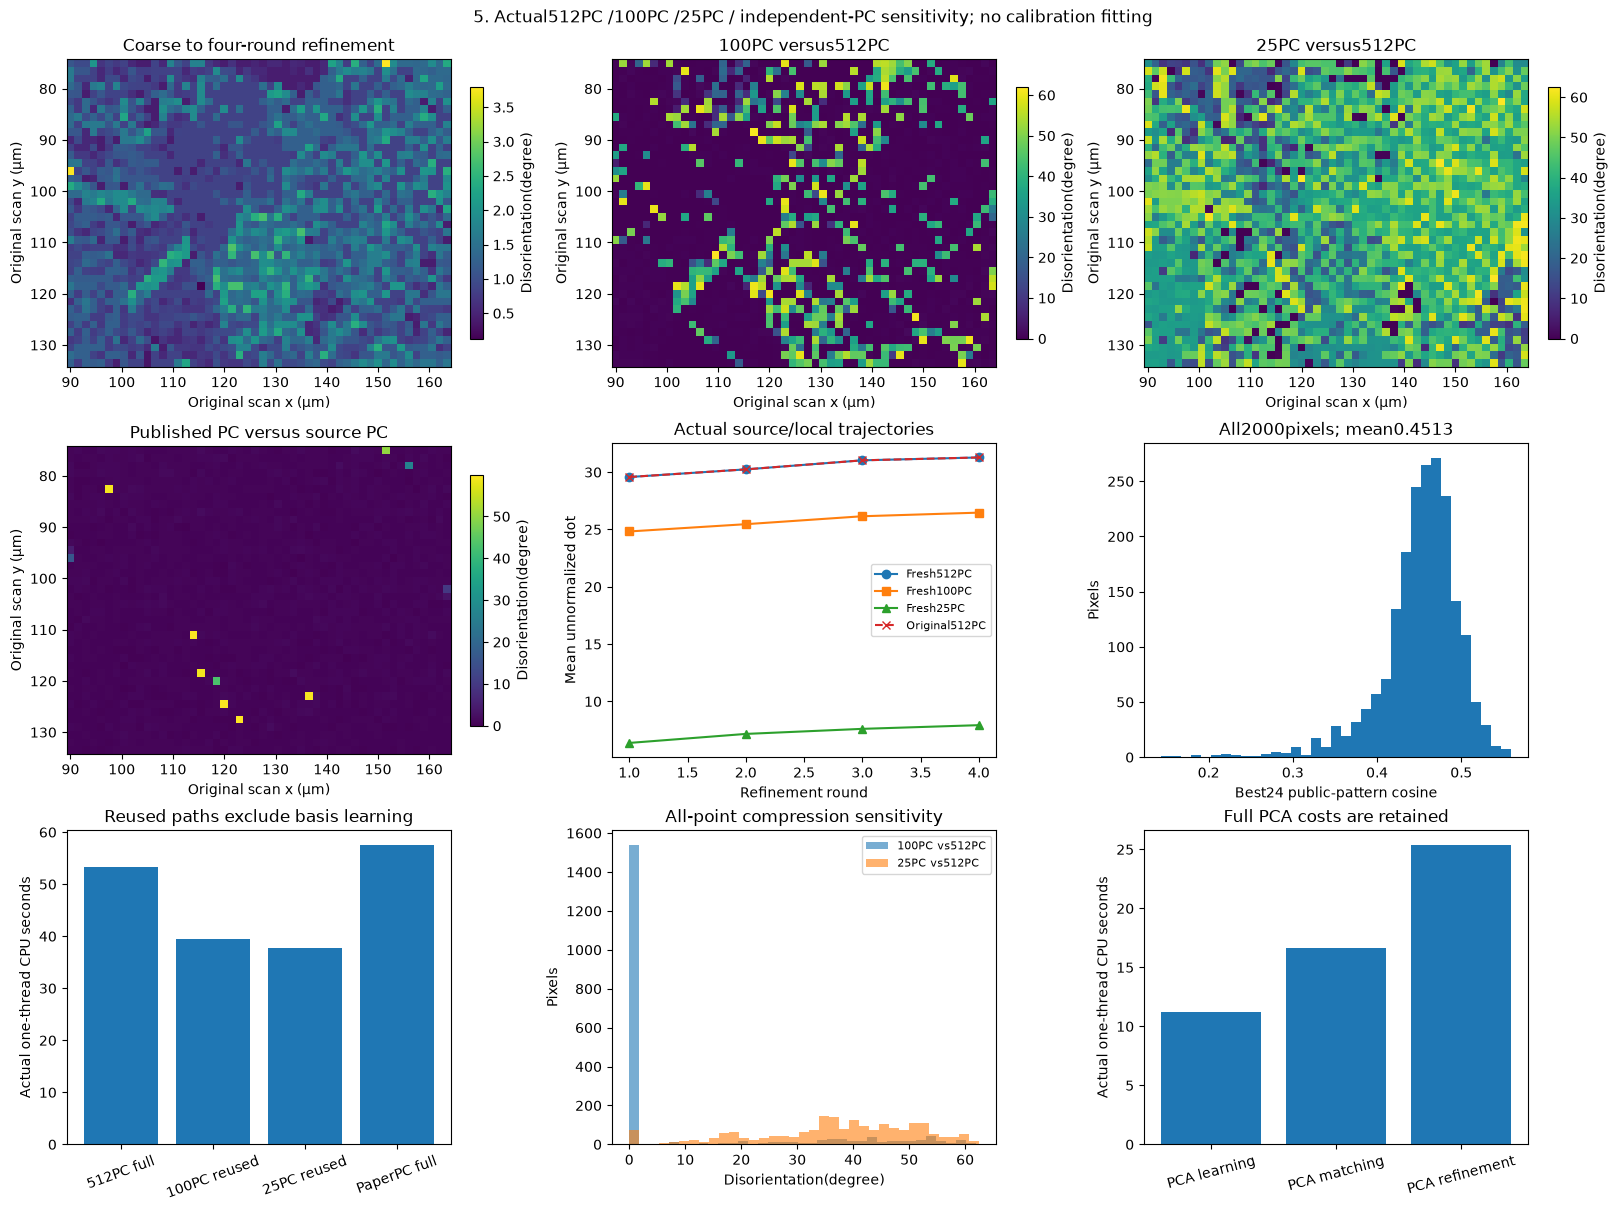

In [7]:
display(figures[4])
plt.close(figures[4])

### Figure6

Actual direct uncompressed dictionary indexing is run on all2000public patterns with the same102448orientation dictionary and four refinement rounds. The original direct branch normalizes rays before rotation, simulates all900pixels and then selects716matching pixels; this distinct source convention is preserved. Original and fresh direct-DI maps are compared separately from the512PC map. Matching-only timing excludes PCA learning, preprocessing and refinement; it is not a paper speedup or an orientation-truth accuracy claim. This selected2degree direct comparison is not the paper1degree method reference.


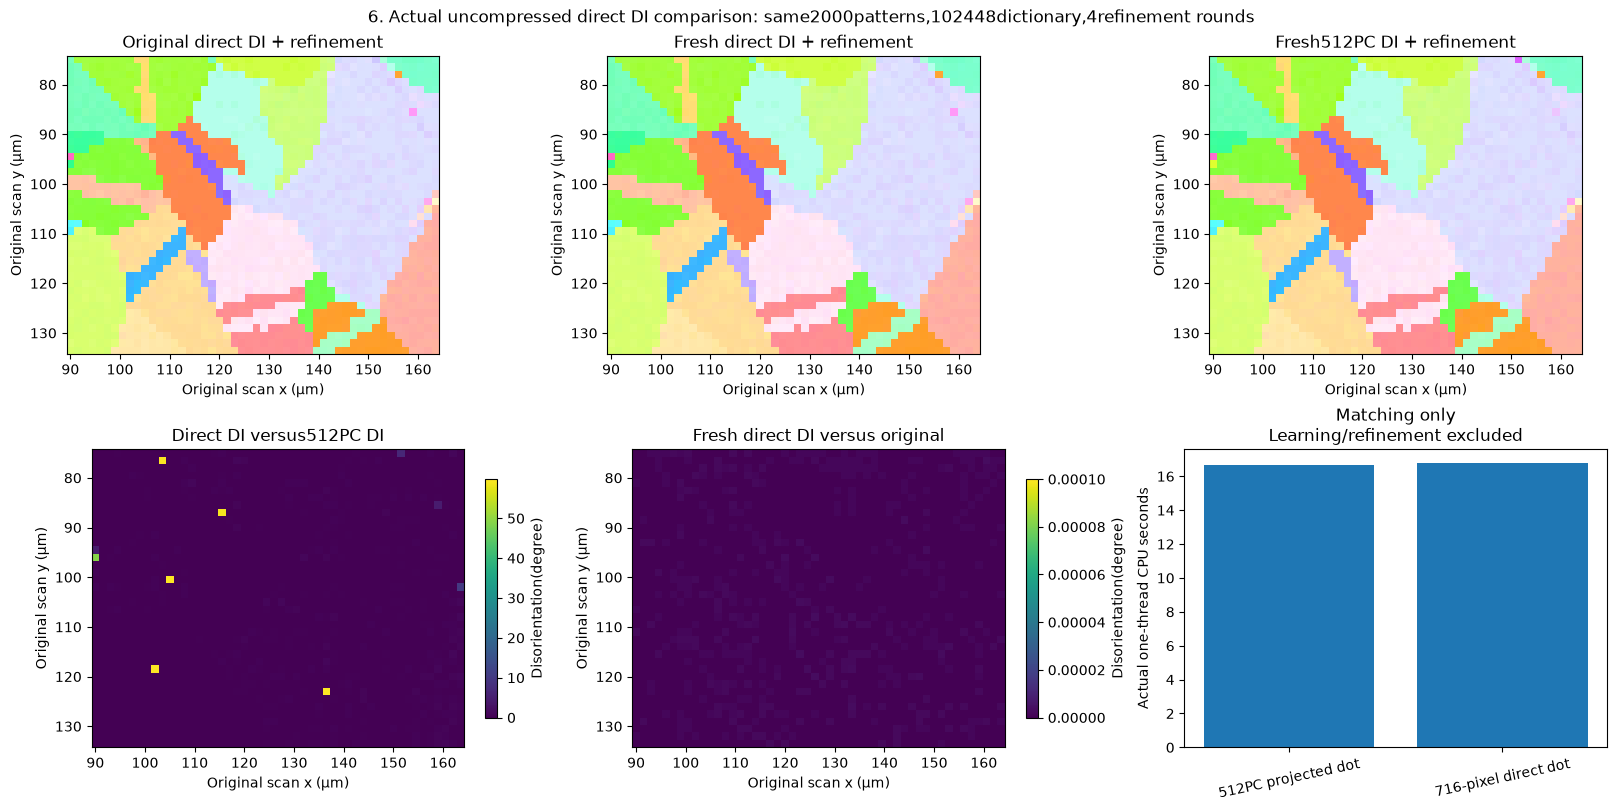

In [8]:
display(figures[5])
plt.close(figures[5])

## 6. Conclusion

### Evaluation and limitations

All2000unit quaternion outputs are evaluated with q/-q and24left-cubic symmetry, without spatial registration. Standard-reference maximum/mean disorientation thresholds1e-4/1e-5degrees cover numerical float32 representation, supported by independent one-ULP and self-roundoff cases; they are not measured physical accuracy. Independent NumPy public-only preprocessing, Bruker geometry, Lambert mapping and bilinear sampling provide a second observation-consistency metric. Its modest mean pattern cosine is reported honestly and the basis/PC/residual comparisons show the remaining model dependence. No method estimate is labeled truth. The task does not claim the paper's full1degree-DI reference, training/precision/noise benchmarks or an absolute orientation calibration beyond supplied independent parameters.

PCA/reference disorientation tests numerical orientation agreement after cubic symmetry, while modest pattern cosine measures model fit. Neither makes the simulated master an orientation truth. Detector endpoint and quaternion-representative corrections remain explicitly separated from the historical source configuration.
